# Unbinned maximum-likelihood fit with `iminuit`

This notebook develops an unbinned maximum-likelihood fit step by step. We fit the distribution of
$x=\cos\theta$ with the two-parameter probability density

$f(x\mid a,b)=\frac{1+a x+b x^2}{I(a,b)},\qquad x_{\min}\leq x\leq x_{\max}$

where $I(a,b)$ normalizes the density to unit integral.

**Learning goals**

1. Load and inspect a one-dimensional sample.
2. Understand why an unbinned likelihood uses the individual event values.
3. Define a normalized probability density and fit its parameters with `iminuit`.
4. Inspect fit quality, parameter uncertainties, correlations, and likelihood contours.

> The histogram is used for visualization only. The fit itself uses the unbinned event values.

In [3]:
# If needed, install iminuit in your environment:
!pip install iminuit

import numpy as np
import matplotlib.pyplot as plt
from iminuit import Minuit
from iminuit.cost import UnbinnedNLL

print("NumPy:", np.__version__)
import iminuit
print("iminuit:", iminuit.__version__)

NumPy: 2.4.6
iminuit: 2.33.0


## 1. Load the data

The original example uses a text file hosted by Heidelberg University, but in git you can find it. If the download is unavailable,
the cell creates a reproducible toy sample so that the rest of the notebook can still be run.

The fit range is fixed to $[-0.95,0.95]$, as in the original example.

In [4]:
XMIN, XMAX = -0.95, 0.95
DATA_URL = (
    "https://github.com/erossi2/AnalisiDati_aa2026-27/blob/main/Likelihood%26OtherTests/data_ml_fit.txt"
)

try:
    data = np.loadtxt(DATA_URL)
    data_source = "Heidelberg example dataset"
except Exception as err:
    print(f"Could not download the example data ({err}).")
    print("Generating a reproducible toy sample instead.")

    rng = np.random.default_rng(2025)
    a_true, b_true = 0.35, 0.25

    def pdf_unnormalized(x, a, b):
        return 1.0 + a*x + b*x**2

    # Rejection sampling. The envelope is evaluated on a dense grid.
    grid = np.linspace(XMIN, XMAX, 2000)
    envelope = pdf_unnormalized(grid, a_true, b_true).max()
    accepted = []
    while len(accepted) < 1000:
        candidates = rng.uniform(XMIN, XMAX, 3000)
        keep = rng.uniform(0, envelope, candidates.size) < pdf_unnormalized(
            candidates, a_true, b_true
        )
        accepted.extend(candidates[keep].tolist())
    data = np.asarray(accepted[:1000])
    data_source = "toy sample (a=0.35, b=0.25)"

data = np.asarray(data, dtype=float).ravel()
data = data[np.isfinite(data)]
data = data[(data >= XMIN) & (data <= XMAX)]

if data.size == 0:
    raise ValueError("No finite events remain inside the fit range.")

print(f"Data source: {data_source}")
print(f"Number of events in fit range: {data.size}")
print(f"Minimum / maximum: {data.min():.4f} / {data.max():.4f}")

Could not download the example data (could not convert string '<!DOCTYPE' to float64 at row 0, column 1.).
Generating a reproducible toy sample instead.
Data source: toy sample (a=0.35, b=0.25)
Number of events in fit range: 1000
Minimum / maximum: -0.9452 / 0.9466


## 2. Inspect the sample

A histogram helps us understand the shape of the data. The choice of binning affects the appearance
of the histogram, but **does not affect the unbinned fit**.

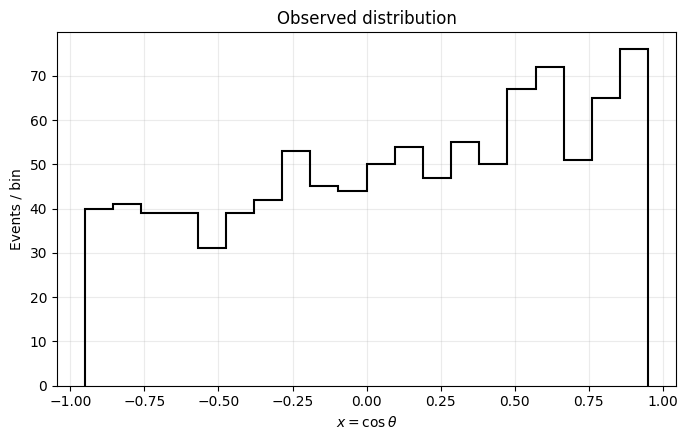

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(data, bins=20, range=(XMIN, XMAX), histtype="step",
        color="black", linewidth=1.5)
ax.set(
    xlabel=r"$x=\cos\theta$",
    ylabel="Events / bin",
    title="Observed distribution",
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Define the normalized probability density

The unnormalized shape is $g(x;a,b)=1+ax+bx^2$. Its integral over the fit range is

$I(a,b)=(x_{\max}-x_{\min})
+a\frac{x_{\max}^2-x_{\min}^2}{2}
+b\frac{x_{\max}^3-x_{\min}^3}{3}$.

Therefore $f=g/I$ integrates to one over the fit range.

A valid probability density must be non-negative throughout the fit range. The function below returns
`NaN` if a proposed parameter point is invalid; the objective function will then reject that point.

In [10]:
import scipy as scipy
from scipy import stats

def normalization(a, b):
    """Integral of 1 + a*x + b*x**2 over the fit range."""
    return (
        (XMAX - XMIN)
        + 0.5 * a * (XMAX**2 - XMIN**2)
        + (b / 3.0) * (XMAX**3 - XMIN**3)
    )


def pdf(x, a, b):
    """Normalized probability density on [XMIN, XMAX]."""
    x = np.asarray(x)
    numerator = 1.0 + a*x + b*x**2
    norm = normalization(a, b)

    # Reject parameter points that do not define a physical PDF.
    if norm <= 0 or np.any(numerator <= 0):
        return np.full_like(x, np.nan, dtype=float)

    return numerator / norm


# Sanity check: numerical integration should be approximately one.
x_check = np.linspace(XMIN, XMAX, 10000)
print("Numerical integral:", scipy.stats.trapezoid(pdf(x_check, 0.2, 0.1), x_check))

Numerical integral: <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7b0662774830>


## 4. Build the unbinned negative log-likelihood

For independent observations \(x_1,\ldots,x_N\), the likelihood is

$L(a,b)=\prod_{k=1}^{N} f(x_k\mid a,b)$.

It is numerically more stable to minimize the negative log-likelihood,

$-\log L(a,b)=-\sum_{k=1}^{N}\log f(x_k\mid a,b)$.

`iminuit.cost.UnbinnedNLL` constructs this objective for us. Its model function must return the
normalized density evaluated at the observed data points.

In [11]:
nll = UnbinnedNLL(data, pdf)

# Starting values are initial guesses, not fixed parameter values.
m = Minuit(nll, a=0.0, b=0.0)

# For a negative log-likelihood, Minuit's default errordef is appropriate:
# Minuit.LIKELIHOOD = 0.5, corresponding to a change of 0.5 in -log(L)
# for a one-parameter 1-sigma interval.
print("errordef:", m.errordef)
print("Initial NLL:", m.fval)

errordef: 1.0
Initial NLL: None


## 5. Minimize and estimate uncertainties

- `migrad()` searches for the parameter values that minimize the NLL.
- `hesse()` estimates local uncertainties from the curvature around the minimum.
- `minos()` can provide profile-likelihood uncertainties; it is useful when the likelihood is
  noticeably non-parabolic or parameters are close to boundaries.

In [12]:
m.migrad()
m.hesse()

print("Valid minimum:", m.valid)
print("Function calls:", m.nfcn)
print(f"Minimum NLL: {m.fval:.3f}")
print()
for name in m.parameters:
    print(f"{name:>4s} = {m.values[name]: .5f} +/- {m.errors[name]:.5f}")

print("\nCorrelation matrix:")
print(m.covariance.correlation())

Valid minimum: True
Function calls: 44
Minimum NLL: 1242.787

   a =  0.38502 +/- 0.06530
   b =  0.20042 +/- 0.12987

Correlation matrix:
┌───┬─────────┐
│   │   a   b │
├───┼─────────┤
│ a │   1 0.4 │
│ b │ 0.4   1 │
└───┴─────────┘


In [13]:
# Optional: profile-likelihood uncertainties.
# This may take longer than HESSE.
m.minos()
for name in m.parameters:
    err = m.merrors[name]
    print(f"{name}: lower={err.lower:.5f}, upper={err.upper:.5f}, "
          f"valid={err.is_valid}")

a: lower=-0.06392, upper=0.06689, valid=True
b: lower=-0.12417, upper=0.13603, valid=True


## 6. Overlay the fitted PDF on the data

The histogram is normalized to unit area, so it can be compared directly with the fitted probability
density. The curve is evaluated only inside the fit range.

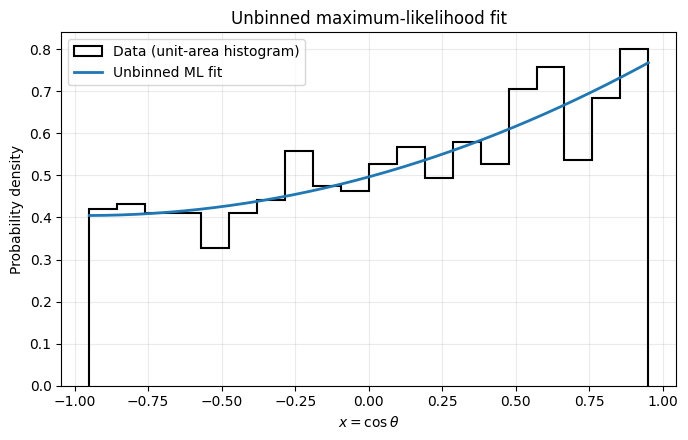

In [14]:
a_fit, b_fit = m.values["a"], m.values["b"]
x_plot = np.linspace(XMIN, XMAX, 500)
y_plot = pdf(x_plot, a_fit, b_fit)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(data, bins=20, range=(XMIN, XMAX), density=True,
        histtype="step", color="black", linewidth=1.5,
        label="Data (unit-area histogram)")
ax.plot(x_plot, y_plot, linewidth=2, label="Unbinned ML fit")
ax.set(
    xlabel=r"$x=\cos\theta$",
    ylabel="Probability density",
    title="Unbinned maximum-likelihood fit",
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Two-parameter likelihood contours

The contour plot shows how the fit quality changes when both parameters vary. The best-fit point is
the minimum of the NLL. For two parameters, the usual likelihood-ratio confidence regions correspond
to fixed increases in the NLL:

- 68.3% joint confidence: \(\Delta(-\log L)=1.15\)
- 95.0% joint confidence: \(\Delta(-\log L)=3.00\)
- 99.7% joint confidence: \(\Delta(-\log L)=4.50\)

These are **two-dimensional** confidence regions. They are not the same as drawing 1, 2, and 3
one-dimensional standard-deviation ellipses.

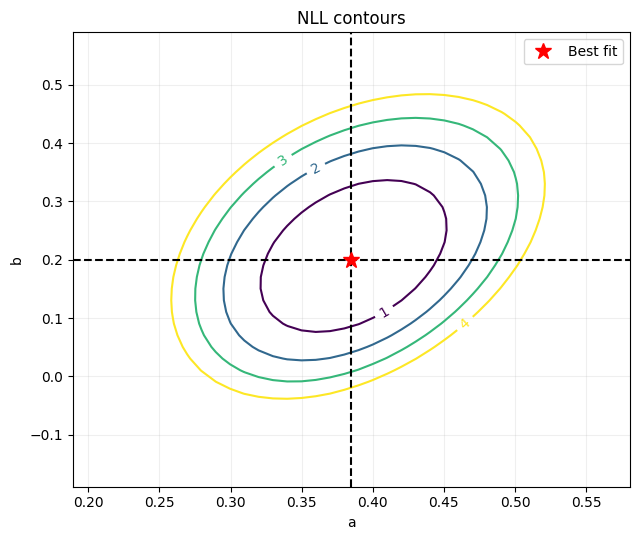

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
m.draw_contour("a", "b", size=40, bound=3, x=ax)
ax.plot(a_fit, b_fit, "r*", markersize=12, label="Best fit")
ax.set_xlabel("a")
ax.set_ylabel("b")
ax.set_title("NLL contours")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Covariance matrix and confidence ellipse

Near the minimum, the NLL is approximately quadratic and the parameter uncertainties are described
by the covariance matrix. The ellipse below uses the covariance matrix and the chi-square quantiles
for **two** degrees of freedom.

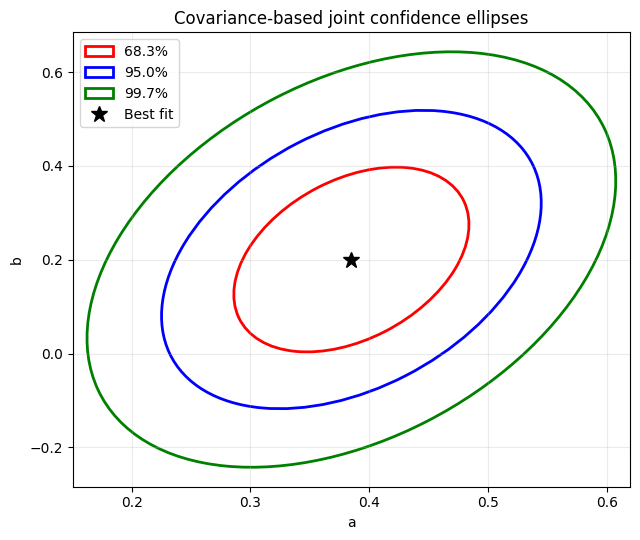

In [25]:
from matplotlib.patches import Ellipse
from scipy.stats import chi2

cov = np.asarray(m.covariance)
center = np.array([a_fit, b_fit])

# Eigenvectors give the ellipse orientation; eigenvalues give its squared axes.
eigenvalues, eigenvectors = np.linalg.eigh(cov)
if np.any(eigenvalues <= 0):
    raise ValueError("Covariance matrix is not positive definite.")

angle = np.degrees(np.arctan2(eigenvectors[1, 1], eigenvectors[0, 1]))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
confidence_levels = [(0.683, "68.3%", 'red'), (0.950, "95.0%",'blue'), (0.997, "99.7%", 'green')]
for confidence, label, col in confidence_levels:
    scale = np.sqrt(chi2.ppf(confidence, df=2))
    width, height = 2 * scale * np.sqrt(eigenvalues[::-1])
    ellipse = Ellipse(
        xy=center, width=width, height=height, angle=angle,
        fill=False, linewidth=2, label=label, ec=col
    )
    ax.add_patch(ellipse)

ax.plot(*center, "k*", markersize=12, label="Best fit")
ax.set_xlabel("a")
ax.set_ylabel("b")
ax.set_title("Covariance-based joint confidence ellipses")
ax.legend()
ax.grid(alpha=0.25)
ax.relim()
ax.autoscale_view()
plt.tight_layout()
plt.show()

## 9. Interpretation and limitations

- The fitted values are maximum-likelihood estimates of \(a\) and \(b\).
- HESSE uncertainties rely on a local quadratic approximation to the NLL.
- MINOS uncertainties use profile likelihood and can be asymmetric.
- The covariance ellipse is also a local approximation. If the PDF positivity boundary is nearby,
  the likelihood contours may be non-elliptical and the Gaussian approximation may be poor.
- A histogram overlay is a visual diagnostic, not a complete goodness-of-fit test.

### A few exercises

1. Change the histogram binning. Does the fitted result change? Why not?
2. Start Minuit from different initial values. Does it find the same minimum?
3. Compare HESSE and MINOS uncertainties.
4. Repeat the fit with a smaller sample. How do the uncertainties change?
5. If using the toy sample, compare the fitted values with the generating values \(a=0.35\) and \(b=0.25\).

### References

- [iminuit documentation](https://iminuit.readthedocs.io/)
- [UnbinnedNLL documentation](https://iminuit.readthedocs.io/en/stable/reference.html#iminuit.cost.UnbinnedNLL)
